In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Localizar o arquivo CSV
caminho = Path("../regressao/dados/partidas_simuladas.csv")

if not caminho.exists():
    caminho = Path("regressao/dados/partidas_simuladas.csv")

# Carregar os dados
df = pd.read_csv(caminho)

# Configuração dos gráficos
sns.set_theme(style="whitegrid")

print("DADOS CARREGADOS COM SUCESSO!")
print("Quantidade de registros:", len(df))
print("Quantidade de colunas:", len(df.columns))

display(df.head())

DADOS CARREGADOS COM SUCESSO!
Quantidade de registros: 600
Quantidade de colunas: 9


,id_partida,zumbis_derrotados,distancia_percorrida_m,dano_recebido,itens_coletados,salas_exploradas,dificuldade,tempo_conclusao_min,origem_dados
0,1,7,402,94,8,5,facil,29.31,simulados
1,2,34,656,75,13,2,facil,33.82,simulados
2,3,5,1195,29,0,10,facil,32.26,simulados
3,4,26,1202,57,8,2,facil,28.09,simulados
4,5,27,1693,35,4,5,medio,44.00,simulados


In [3]:
# Informações gerais
df.info()

print("\nValores ausentes:")
display(df.isnull().sum())

print("\nRegistros duplicados:")
print(df.duplicated().sum())

print("\nEstatísticas descritivas:")
display(df.describe())

<class 'pandas.DataFrame'>
RangeIndex: 600 entries, 0 to 599
Data columns (total 9 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   id_partida              600 non-null    int64  
 1   zumbis_derrotados       600 non-null    int64  
 2   distancia_percorrida_m  600 non-null    int64  
 3   dano_recebido           600 non-null    int64  
 4   itens_coletados         600 non-null    int64  
 5   salas_exploradas        600 non-null    int64  
 6   dificuldade             600 non-null    str    
 7   tempo_conclusao_min     600 non-null    float64
 8   origem_dados            600 non-null    str    
dtypes: float64(1), int64(6), str(2)
memory usage: 42.3 KB

Valores ausentes:


id_partida                0
zumbis_derrotados         0
distancia_percorrida_m    0
dano_recebido             0
itens_coletados           0
salas_exploradas          0
dificuldade               0
tempo_conclusao_min       0
origem_dados              0
dtype: int64


Registros duplicados:
0

Estatísticas descritivas:


,id_partida,zumbis_derrotados,distancia_percorrida_m,dano_recebido,itens_coletados,salas_exploradas,tempo_conclusao_min
count,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000,600.000000
mean,300.500000,17.490000,1404.743333,49.605000,7.566667,6.878333,43.399450
std,173.349358,10.386837,630.681112,29.392156,4.519543,3.119789,8.275005
min,1.000000,0.000000,306.000000,0.000000,0.000000,2.000000,21.590000
25%,150.750000,8.000000,857.250000,23.000000,4.000000,4.000000,37.107500
50%,300.500000,18.000000,1437.000000,49.000000,8.000000,7.000000,43.355000
75%,450.250000,26.250000,1942.500000,75.250000,11.000000,9.000000,48.815000
max,600.000000,35.000000,2499.000000,100.000000,15.000000,12.000000,65.470000


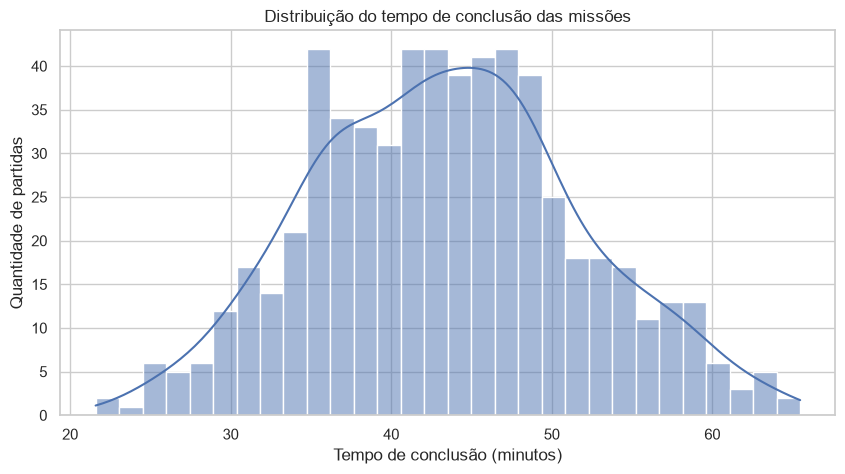

In [4]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df,
    x="tempo_conclusao_min",
    bins=30,
    kde=True
)

plt.title("Distribuição do tempo de conclusão das missões")
plt.xlabel("Tempo de conclusão (minutos)")
plt.ylabel("Quantidade de partidas")

plt.show()

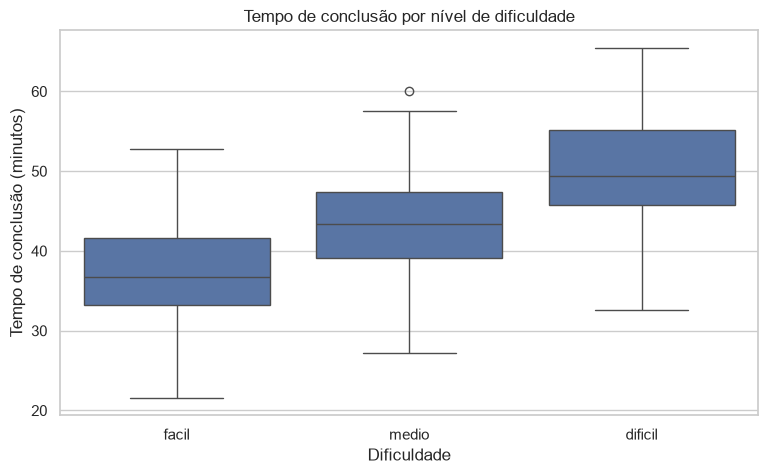

In [5]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="dificuldade",
    y="tempo_conclusao_min"
)

plt.title("Tempo de conclusão por nível de dificuldade")
plt.xlabel("Dificuldade")
plt.ylabel("Tempo de conclusão (minutos)")

plt.show()

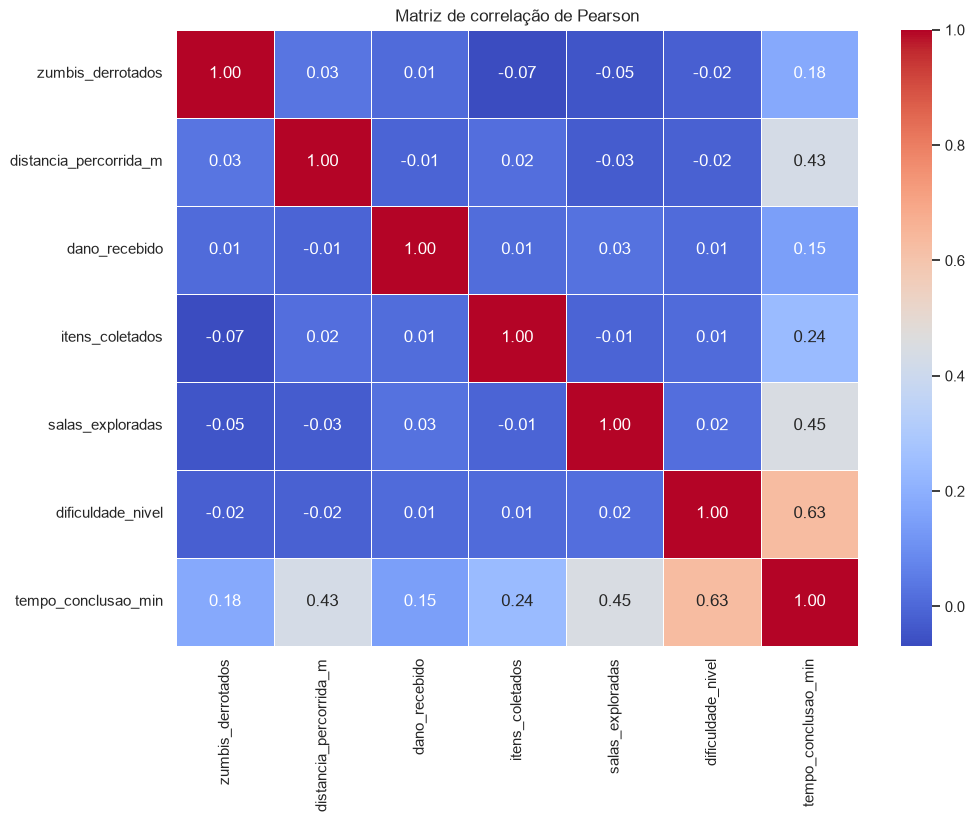

In [6]:
df_correlacao = df.copy()

df_correlacao["dificuldade_nivel"] = (
    df_correlacao["dificuldade"].map({
        "facil": 1,
        "medio": 2,
        "dificil": 3
    })
)

colunas_numericas = [
    "zumbis_derrotados",
    "distancia_percorrida_m",
    "dano_recebido",
    "itens_coletados",
    "salas_exploradas",
    "dificuldade_nivel",
    "tempo_conclusao_min"
]

matriz = df_correlacao[colunas_numericas].corr(method="pearson")

plt.figure(figsize=(11, 8))

sns.heatmap(
    matriz,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Matriz de correlação de Pearson")
plt.show()

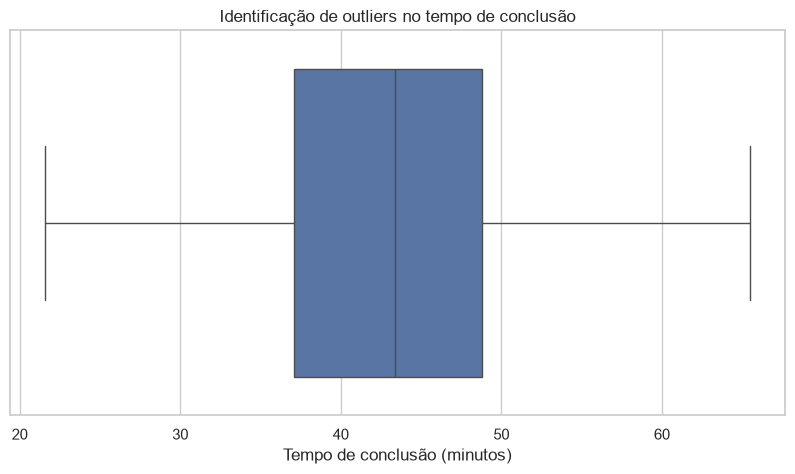

Limite inferior: 19.546250000000008
Limite superior: 66.37625
Quantidade de possíveis outliers: 0


In [7]:
plt.figure(figsize=(10, 5))

sns.boxplot(x=df["tempo_conclusao_min"])

plt.title("Identificação de outliers no tempo de conclusão")
plt.xlabel("Tempo de conclusão (minutos)")

plt.show()

# Método do intervalo interquartil (IQR)
Q1 = df["tempo_conclusao_min"].quantile(0.25)
Q3 = df["tempo_conclusao_min"].quantile(0.75)

IQR = Q3 - Q1

limite_inferior = Q1 - 1.5 * IQR
limite_superior = Q3 + 1.5 * IQR

outliers = df[
    (df["tempo_conclusao_min"] < limite_inferior) |
    (df["tempo_conclusao_min"] > limite_superior)
]

print("Limite inferior:", limite_inferior)
print("Limite superior:", limite_superior)
print("Quantidade de possíveis outliers:", len(outliers))

In [12]:

# Tratamento de outliers pelo método IQR

if len(outliers) > 0:
    df_tratado = df.drop(index=outliers.index).copy()
    print(f"{len(outliers)} registros removidos.")
else:
    df_tratado = df.copy()
    print("Nenhum outlier identificado.")
    print("Todos os 600 registros foram mantidos.")

print("Registros antes do tratamento:", len(df))
print("Registros depois do tratamento:", len(df_tratado))


Nenhum outlier identificado.
Todos os 600 registros foram mantidos.
Registros antes do tratamento: 600
Registros depois do tratamento: 600


In [8]:
display(matriz.round(3))

,zumbis_derrotados,distancia_percorrida_m,dano_recebido,itens_coletados,salas_exploradas,dificuldade_nivel,tempo_conclusao_min
zumbis_derrotados,1.000,0.034,0.009,-0.068,-0.045,-0.018,0.182
distancia_percorrida_m,0.034,1.000,-0.009,0.015,-0.028,-0.016,0.431
dano_recebido,0.009,-0.009,1.000,0.015,0.026,0.008,0.147
itens_coletados,-0.068,0.015,0.015,1.000,-0.008,0.010,0.236
salas_exploradas,-0.045,-0.028,0.026,-0.008,1.000,0.018,0.448
dificuldade_nivel,-0.018,-0.016,0.008,0.010,0.018,1.000,0.632
tempo_conclusao_min,0.182,0.431,0.147,0.236,0.448,0.632,1.000


### Conclusão da Análise Exploratória de Dados

A base utilizada contém 600 registros simulados de partidas do Campos Zone, com seis variáveis explicativas e uma variável-alvo: o tempo de conclusão da missão.

Inicialmente, foram verificadas a estrutura dos dados, a presença de valores ausentes e registros duplicados. Não foram identificados valores nulos ou duplicidades.

A distribuição do tempo de conclusão foi analisada por meio de histogramas e boxplots. Para a identificação de possíveis valores discrepantes, foi aplicado o método do intervalo interquartil (IQR). Não foram encontrados outliers na variável-alvo, portanto, nenhum registro precisou ser removido, mantendo-se os 600 registros originais.

A matriz de correlação de Pearson indicou que a dificuldade apresentou a maior correlação positiva com o tempo de conclusão (0,632), seguida por salas exploradas (0,448) e distância percorrida (0,431).

Esses resultados indicam associações lineares entre as variáveis analisadas. Como os dados são simulados, as relações observadas refletem a lógica utilizada na geração da base.

Após a análise e a verificação de outliers, os dados foram considerados prontos para o treinamento e a comparação dos modelos de regressão.

In [9]:

import pandas as pd
import numpy as np
import joblib

from pathlib import Path

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

# Carregar novamente a base
caminho = Path("../regressao/dados/partidas_simuladas.csv")

if not caminho.exists():
    caminho = Path("regressao/dados/partidas_simuladas.csv")

df = pd.read_csv(caminho)

# Variável que queremos prever
alvo = "tempo_conclusao_min"

# Remover identificador e origem dos dados
X = df.drop(columns=[
    "id_partida",
    "tempo_conclusao_min",
    "origem_dados"
])

y = df[alvo]

# Identificar variáveis numéricas e categóricas
colunas_numericas = [
    "zumbis_derrotados",
    "distancia_percorrida_m",
    "dano_recebido",
    "itens_coletados",
    "salas_exploradas"
]

colunas_categoricas = ["dificuldade"]

# Dividir os dados em treinamento e teste
X_treino, X_teste, y_treino, y_teste = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42
)

print("Dados preparados!")
print("Registros para treinamento:", len(X_treino))
print("Registros para teste:", len(X_teste))


Dados preparados!
Registros para treinamento: 480
Registros para teste: 120


In [10]:

# Pré-processamento das variáveis
preprocessador = ColumnTransformer(
    transformers=[
        (
            "numericas",
            StandardScaler(),
            colunas_numericas
        ),
        (
            "categoricas",
            OneHotEncoder(handle_unknown="ignore"),
            colunas_categoricas
        )
    ]
)

# Criar os dois modelos
modelos = {
    "Regressao Linear": LinearRegression(),

    "Random Forest": RandomForestRegressor(
        n_estimators=100,
        random_state=42,
        max_depth=10
    )
}

resultados_modelos = []
modelos_treinados = {}

# Treinar e avaliar cada modelo
for nome, algoritmo in modelos.items():

    pipeline = Pipeline([
        ("preprocessamento", preprocessador),
        ("modelo", algoritmo)
    ])

    # Treinamento
    pipeline.fit(X_treino, y_treino)

    # Previsões
    previsoes = pipeline.predict(X_teste)

    # Métricas
    mae = mean_absolute_error(y_teste, previsoes)
    mse = mean_squared_error(y_teste, previsoes)
    rmse = np.sqrt(mse)
    r2 = r2_score(y_teste, previsoes)

    resultados_modelos.append({
        "Modelo": nome,
        "MAE": mae,
        "MSE": mse,
        "RMSE": rmse,
        "R2": r2
    })

    modelos_treinados[nome] = pipeline

# Exibir comparação
tabela_resultados = pd.DataFrame(resultados_modelos)

display(
    tabela_resultados.round(4)
)


,Modelo,MAE,MSE,RMSE,R2
0,Regressao Linear,1.8632,5.2119,2.2830,0.9276
1,Random Forest,2.6522,10.8920,3.3003,0.8487


In [11]:

# Escolher o modelo com menor RMSE
melhor_modelo_nome = tabela_resultados.loc[
    tabela_resultados["RMSE"].idxmin(),
    "Modelo"
]

melhor_modelo = modelos_treinados[melhor_modelo_nome]

# Criar pasta para salvar o modelo
pasta_modelos = Path("../regressao/modelos")

if not pasta_modelos.exists():
    pasta_modelos = Path("regressao/modelos")

pasta_modelos.mkdir(parents=True, exist_ok=True)

# Salvar o pipeline completo
caminho_modelo = pasta_modelos / "melhor_modelo.joblib"

joblib.dump(melhor_modelo, caminho_modelo)

# Salvar tabela de comparação
pasta_resultados = Path("../resultados")

if not pasta_resultados.exists():
    pasta_resultados = Path("resultados")

pasta_resultados.mkdir(parents=True, exist_ok=True)

tabela_resultados.to_csv(
    pasta_resultados / "comparacao_modelos.csv",
    index=False,
    encoding="utf-8-sig"
)

print("Melhor modelo:", melhor_modelo_nome)
print("Menor RMSE:", round(
    tabela_resultados["RMSE"].min(), 4
))
print("Modelo salvo em:", caminho_modelo)
print("Comparação salva em:", pasta_resultados)


Melhor modelo: Regressao Linear
Menor RMSE: 2.283
Modelo salvo em: regressao\modelos\melhor_modelo.joblib
Comparação salva em: ..\resultados
